# Zadanie domowe - EDA Danych dotyczących Irysów

* Twoim zadaniem jest wykonanie analizy danych zawartych w załączonym pliku CSV (`25__iris.csv`).
* Plik znajduje się pod video. Pamiętaj, żeby wrzucić plik do tego samego folderu, w którym znajduje się ten notebook.
* Wykorzystaj nowo nabytą wiedzę z biblioteki `Pandas`
* Jeżeli jest taka konieczność posiłkuj się [code explainerem](https://codeexplainer.imprv.ai/) lub / i [data chatterem](https://datachatter.imprv.ai/) (który również te dane ma dostępne).
* Prześlij na discordzie notebook z rozwiązaniem (`#modul-4-zad1`)
* Pamiętaj:

1. Nie spiesz się
2. Potraktuj zadanie domowe jak prawdziwy projekt
3. Dodawaj opisy, obserwacje, wnioski
4. Dodaj wizualizacje
5. Dodaj konkluzję i wnioski końcowe

Powodzenia!!! I mega zabawy!

## O Danych

Zbiór danych zawiera informacje o trzech gatunkach irysów: Iris setosa, Iris versicolor, i Iris virginica.

Dane obejmują pomiary czterech cech: długość i szerokość działki kielicha oraz długość i szerokość płatka.

Każdy wiersz w zbiorze danych reprezentuje pojedynczy kwiat, a wartości pomiarów są podane w centymetrach.

Zbiór składa się z 150 próbek, po 50 dla każdego gatunku, i jest szeroko stosowany jako podstawowy zbiór danych do
testowania algorytmów klasyfikacji oraz w nauce o danych i uczeniu maszynowym.

Kolumny:
* **długość kielicha (sepal length)** - Długość kielicha w cm
* **szerokość kielicha (sepal width)** - Szerokość kielicha w cm
* **długość płatka (petal length)** - Długość płatka w cm
* **szerokość płatka (petal width)** - Szerokość płatka w cm
* **klasa (class)** - Klasa irysa (setosa, versicolor, virginica)

In [3]:
import pandas as pd

In [4]:
df = pd.read_csv('25__iris.csv', sep=",")
df

,długość kielicha (sepal length),szerokość kielicha (sepal width),długość płatka (petal length),szerokość płatka (petal width),klasa (class)
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica


## Pokaż 10 losowych rekordów

In [5]:
df.sample(10)

,długość kielicha (sepal length),szerokość kielicha (sepal width),długość płatka (petal length),szerokość płatka (petal width),klasa (class)
82,5.8,2.7,3.9,1.2,Iris-versicolor
10,5.4,3.7,1.5,0.2,Iris-setosa
100,6.3,3.3,6.0,2.5,Iris-virginica
132,6.4,2.8,5.6,2.2,Iris-virginica
28,5.2,3.4,1.4,0.2,Iris-setosa
13,4.3,3.0,1.1,0.1,Iris-setosa
6,4.6,3.4,1.4,0.3,Iris-setosa
24,4.8,3.4,1.9,0.2,Iris-setosa
97,6.2,2.9,4.3,1.3,Iris-versicolor
149,5.9,3.0,5.1,1.8,Iris-virginica


## Pokaż podsumownaie informacji na temat każdej z kolumn

In [6]:
def show_column_summary(df: pd.DataFrame) -> pd.DataFrame:
    """
    Displays summary information for each column in the DataFrame.

    Parameters:
    df (pd.DataFrame): The pandas DataFrame for which to display column summaries.

    Returns:
    pd.DataFrame: A DataFrame containing summary statistics of each column.
    """
    return df.describe(include='all')

summary = show_column_summary(df)
df.info()
print("---------------------------------------------------------------------------------------")
print(summary)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   długość kielicha (sepal length)   150 non-null    float64
 1   szerokość kielicha (sepal width)  150 non-null    float64
 2   długość płatka (petal length)     150 non-null    float64
 3   szerokość płatka (petal width)    150 non-null    float64
 4   klasa (class)                     150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB
---------------------------------------------------------------------------------------
        długość kielicha (sepal length)  szerokość kielicha (sepal width)  \
count                        150.000000                        150.000000   
unique                              NaN                               NaN   
top                                 NaN                               NaN   
freq   

## Pokaż wszystkie gatunki irysów uwzględnione w analizie

In [7]:
for (i, gatunek) in enumerate(df["klasa (class)"].unique().tolist()):
    print(i+1, '\b. ', gatunek)
    

1.  Iris-setosa
2.  Iris-versicolor
3.  Iris-virginica


## Pokaż podsumowanie na temat wartości z każdej kolumn uwzględniając podział na różne gatunki kwiatów

In [8]:
def summarize_by_column(df: pd.DataFrame, group_by_column: str) -> pd.DataFrame:
    """
    Generates a summary of information for each column in the dataframe,
    grouped by the values of a specified column.

    Args:
    df (pd.DataFrame): The input dataframe.
    group_by_column (str): The name of the column to group by.

    Returns:
    pd.DataFrame: A summary dataframe showing information for each column.
    """
    summary = df.groupby(group_by_column).describe(include = "all")
    return summary

# Example usage
if __name__ == "__main__":
    class_category = "klasa (class)"
    summary_df = summarize_by_column(df, class_category)
    print(summary_df)

                długość kielicha (sepal length)                               \
                                          count   mean       std  min    25%   
klasa (class)                                                                  
Iris-setosa                                50.0  5.006  0.352490  4.3  4.800   
Iris-versicolor                            50.0  5.936  0.516171  4.9  5.600   
Iris-virginica                             50.0  6.588  0.635880  4.9  6.225   

                               szerokość kielicha (sepal width)         ...  \
                 50%  75%  max                            count   mean  ...   
klasa (class)                                                           ...   
Iris-setosa      5.0  5.2  5.8                             50.0  3.418  ...   
Iris-versicolor  5.9  6.3  7.0                             50.0  2.770  ...   
Iris-virginica   6.5  6.9  7.9                             50.0  2.974  ...   

                długość płatka (petal length

In [9]:
def summarize_by_column(df: pd.DataFrame, group_by_category: list[str], category_name:str) -> list[pd.DataFrame]:
    """
    Generates a summary of information for each column in the dataframe,
    grouped by the values of a specified column.

    Args:
    df (pd.DataFrame): The input dataframe.
    group_by_column (str): The name of the column to group by.

    Returns:
    pd.DataFrame: A summary dataframe showing information for each column.
    """
    summary = []
    for cat in group_by_category:
        cat_df = df[df[category_name] == cat]
        summary.append(cat_df.describe(include = "all"))
    return summary

# Example usage
if __name__ == "__main__":
    category_name = "klasa (class)"
    class_categories = df[category_name].unique().tolist()
    summary_df = summarize_by_column(df, class_categories, category_name)
    for (i, summary) in enumerate(summary_df):
        print()
        print(i+1, "\b.", str.upper(class_categories[i]))
        print(summary)


1. IRIS-SETOSA
        długość kielicha (sepal length)  szerokość kielicha (sepal width)  \
count                          50.00000                         50.000000   
unique                              NaN                               NaN   
top                                 NaN                               NaN   
freq                                NaN                               NaN   
mean                            5.00600                          3.418000   
std                             0.35249                          0.381024   
min                             4.30000                          2.300000   
25%                             4.80000                          3.125000   
50%                             5.00000                          3.400000   
75%                             5.20000                          3.675000   
max                             5.80000                          4.400000   

        długość płatka (petal length)  szerokość płatka (pe

 ## Pierwszych 10 rekordów pod względem różnych parametrów analizowanych irysów uporządkowanych malejąco

In [10]:
import pandas as pd

# Sorting and displaying top 10 records for each column in decreasing order
result_dict = {}
columns = df.columns.tolist()
columns.remove("klasa (class)")

for column in columns:
    result_dict[column] = df.sort_values(by=column, ascending=False).head(10)

# Display results
for column, top_records in result_dict.items():
    print(f"Top 10 records sorted by {column} in descending order:")
    print(top_records, "\n")

Top 10 records sorted by długość kielicha (sepal length) in descending order:
     długość kielicha (sepal length)  szerokość kielicha (sepal width)  \
131                              7.9                               3.8   
135                              7.7                               3.0   
122                              7.7                               2.8   
117                              7.7                               3.8   
118                              7.7                               2.6   
105                              7.6                               3.0   
130                              7.4                               2.8   
107                              7.3                               2.9   
125                              7.2                               3.2   
109                              7.2                               3.6   

     długość płatka (petal length)  szerokość płatka (petal width)  \
131                            6.4   

## Wnioski dotyczące pierwszej dziesiątki irysów pod względem różnych ich parametrów.
1. *Iris-virginica* zdominował pierwszą 10 pod względem długości kielicha, w pierwszej 10 nie znalazł się żaden inny gatunek irysa
2. *Iris-setos*a zdominował pierwszą dziesiątkę pod względem szerokości kielicha, na 10 i 9 miejscu znalazły się pojedyncze irys innego gatunku - *Iris-virginica*
4. *Iris virginica* zdominował rónież pierwszą dziesiątkę pod względem długości oraz szerokości płatka. W obu przypadkach, podobnie jak przedtem w pierwszej dziesiątce uwzględniającej najwyższe pomiary, nie znalazły się inne gatunki irysa sposród tych poddawanych analizie.

## Pierwszych 10 rekordów pod względem różnych parametrów analizowanych irysów uporządkowanych rosnąco

In [42]:
import pandas as pd

# Sorting and displaying top 10 records for each column in decreasing order
result_dict = {}
columns = df.columns.tolist()
columns.remove("klasa (class)")

for column in columns:
    result_dict[column] = df.sort_values(by=column, ascending=True).head(10)

# Display results
for column, top_records in result_dict.items():
    print(f"Top 10 records sorted by {column} in asccending order:")
    print(top_records, "\n")

Top 10 records sorted by długość kielicha (sepal length) in asccending order:
    długość kielicha (sepal length)  szerokość kielicha (sepal width)  \
13                              4.3                               3.0   
42                              4.4                               3.2   
38                              4.4                               3.0   
8                               4.4                               2.9   
41                              4.5                               2.3   
22                              4.6                               3.6   
3                               4.6                               3.1   
6                               4.6                               3.4   
47                              4.6                               3.2   
2                               4.7                               3.2   

    długość płatka (petal length)  szerokość płatka (petal width)  \
13                            1.1                

## Wnioski dotyczące pierwszej dziesiątki irysów z najmniejszymi wartościami pomiarów pod względem różnych ich parametrów.

1. *Iris-setosa* zdominował pierwszą 10 pod względem długości kielicha, w pierwszej 10 nie znalazł się żaden inny gatunek irysa. Można zatem wnioskować, że mają one zwykle najkrótsze kielichy spośród analizowanych gatunków.
2. *Iris-versicolor* zdominował pierwszą dziesiątkę pod względem szerokości kielicha, jednak w pierwszej dziesiątce najniższysch pomiarów znajdują się pojedyncze pomiary dla dwóch pozostałych gatunków.
3. *Iris-setosa* zdominował rónież pierwszą dziesiątkę pod względem długości płatka oraz szerokości płatka. W obu przypadkach, podobnie jak przedtem w pierwszej dziesiątce uwzględniającej najniższe pomiary, nie znalazły się inne gatunki irysa sposród tych poddawanych analizie. Można zatem wnioskować, że *Iris-setosa* ma zwykle najwęższe oraz najkrótsze płatki pośród analizowanych trzech gatunków irysa.

In [78]:
columns = df.columns.tolist()
columns.remove("klasa (class)")

# Group data by 'Category' and calculate the average of 'Value' within each group
all_means = {}
for col in columns:
    grouped_df = df.groupby('klasa (class)')[col].mean().sort_values(ascending=False).reset_index()
    all_means[col] = grouped_df

for key, value in all_means.items():
    print()
    print(f"Average {key} for different iris classes:")
    print(value)


Average długość kielicha (sepal length) for different iris classes:
     klasa (class)  długość kielicha (sepal length)
0   Iris-virginica                            6.588
1  Iris-versicolor                            5.936
2      Iris-setosa                            5.006

Average szerokość kielicha (sepal width) for different iris classes:
     klasa (class)  szerokość kielicha (sepal width)
0      Iris-setosa                             3.418
1   Iris-virginica                             2.974
2  Iris-versicolor                             2.770

Average długość płatka (petal length) for different iris classes:
     klasa (class)  długość płatka (petal length)
0   Iris-virginica                          5.552
1  Iris-versicolor                          4.260
2      Iris-setosa                          1.464

Average szerokość płatka (petal width) for different iris classes:
     klasa (class)  szerokość płatka (petal width)
0   Iris-virginica                           2.026
1  I

## Wnioski dotyczące średnich wartości kolumn dla różnych gatunków irysów

1. *Iris-virginica* osiąga najwyższe średnie wartości pod względem długości kielicha, długości płatka oraz szerokosci płatka spośród wszystkich trzech gatunków znajdujących się w analizowanym zbiorze danych.
2. *Iris-setosa* osiąga nawyższą średnią szerokość kielicha spośród porónywanych 3 gatunków irysa
3. *Iris-setosa* osiąga najniższe średnie wartości pod względem długości płatka, długości kielicha oraz szerokości płatka pośród analizowanych trzech gatunków
4. *Iris-versiciolor* osiąga najniższą średnią szerokość kielicha pośród analizowanych gatunków irysa

## Analiza korelacji pomiędzy różnymi parametrami irysów wszystkich trzech analizowanych gatunków

In [11]:
df.corr()

C:\Users\micha\AppData\Local\Temp\ipykernel_48316\1134722465.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  df.corr()


,długość kielicha (sepal length),szerokość kielicha (sepal width),długość płatka (petal length),szerokość płatka (petal width)
długość kielicha (sepal length),1.000000,-0.109369,0.871754,0.817954
szerokość kielicha (sepal width),-0.109369,1.000000,-0.420516,-0.356544
długość płatka (petal length),0.871754,-0.420516,1.000000,0.962757
szerokość płatka (petal width),0.817954,-0.356544,0.962757,1.000000


## Wnioski dotyczące korelacji pomiędzy różnymi właściwościami irysów

1. Długość kielicha koreluje w istotny sposób z długością oraz szerokością płatków.
2. Można zauważyć nieznaczną ujemną korelację pomiędzy długością kielicha a szerokością kielicha. Jednak jest to raczej słaba korelacja.
3. Najsilniejsza zuważalna korelacja występuje pomiędzy dłogoscią płatka a jego szerokoscią.

## Analiza korelacji pomiędzy różnymi parametrami Iris-virginica

In [81]:
df[df["klasa (class)"] == "Iris-virginica"].corr()

C:\Users\micha\AppData\Local\Temp\ipykernel_40680\1597633532.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  df[df["klasa (class)"] == "Iris-virginica"].corr()


,długość kielicha (sepal length),szerokość kielicha (sepal width),długość płatka (petal length),szerokość płatka (petal width)
długość kielicha (sepal length),1.000000,0.457228,0.864225,0.281108
szerokość kielicha (sepal width),0.457228,1.000000,0.401045,0.537728
długość płatka (petal length),0.864225,0.401045,1.000000,0.322108
szerokość płatka (petal width),0.281108,0.537728,0.322108,1.000000


## Korelacje pomiędzy różnymi właściwościami irysów z gatunku Iris-virginica

1. Długość kielicha koreluje z szerokością kielicha w większym stopniu dla Iris-virginica niż miało to w przypadku porównywaniu pomiarów wszystkich irysów. Dodatkowo nie jest to ujemna korelacja jak miało to miejsce przy porównywaniu wszystkich irysów.
2. Długość kielicha koreluje z szerokością płatka w zauważalnie mniejszym stopniu w przypadku Iris-virginica niż miało to miejsce w przypadku porównywania wszystkich pomiarów dla wszystkich gatunków.
3. Długość płatka koreluje w zauważalnie mniejsyzm stopniu z szerokością płatka dla Iris-virginica niż w przypadku analizy wszystkich trzech gatunków.

## Analiza korelacji pomiędzy różnymi parametrami Iris-setosa

In [82]:
df[df["klasa (class)"] == "Iris-setosa"].corr()

C:\Users\micha\AppData\Local\Temp\ipykernel_40680\4134523024.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  df[df["klasa (class)"] == "Iris-setosa"].corr()


,długość kielicha (sepal length),szerokość kielicha (sepal width),długość płatka (petal length),szerokość płatka (petal width)
długość kielicha (sepal length),1.000000,0.746780,0.263874,0.279092
szerokość kielicha (sepal width),0.746780,1.000000,0.176695,0.279973
długość płatka (petal length),0.263874,0.176695,1.000000,0.306308
szerokość płatka (petal width),0.279092,0.279973,0.306308,1.000000


## Korelacje pomiędzy różnymi właściwościami irysów z gatunku Iris-setosa

1. Długość kielicha koreluje z szerokością kielicha w większym stopniu dla Iris-setosa niż miało to w przypadku porównywaniu pomiarów wszystkich irysów, a także w większym stopniu niż dla Iris-virginica. Dodatkowo nie jest to ujemna korelacja jak miało to miejsce przy porównywaniu wszystkich irysów (podbnie jak dla Iris-virginica).
2. Długość kielicha koreluje z szerokością płatka w zauważalnie mniejszym stopniu w przypadku Iris-setosa niż miało to miejsce w przypadku porównywania wszystkich pomiarów dla wszystkich gatunków, ale wartość wpółczynnika korelcji jest podobna do tej obserwowanej dla Iris-viriginica.
3. Długość płatka koreluje w znacznie mniejszym stopniu z szerokością płatka dla Iris-setosa niż w przypadku analizy wszystkich trzech gatunków. Dodatkowo wspóczynnik korelacji pomiędzy tymi wartościami jest podobny do wpołczynnika korelacji pomiędzy długością kielicha a szerokością płatka, który został opisany powyżej. Jest to też wartość podobna do wpółczynnika korelacji pomiędzy szerokoscią kielicha a szerokością płatka.

## Analiza korelacji pomiędzy różnymi parametrami Iris-versicolor

In [85]:
df[df["klasa (class)"] == "Iris-versicolor"].corr()

C:\Users\micha\AppData\Local\Temp\ipykernel_40680\3369704009.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  df[df["klasa (class)"] == "Iris-versicolor"].corr()


,długość kielicha (sepal length),szerokość kielicha (sepal width),długość płatka (petal length),szerokość płatka (petal width)
długość kielicha (sepal length),1.000000,0.525911,0.754049,0.546461
szerokość kielicha (sepal width),0.525911,1.000000,0.560522,0.663999
długość płatka (petal length),0.754049,0.560522,1.000000,0.786668
szerokość płatka (petal width),0.546461,0.663999,0.786668,1.000000


## Korelacje pomiędzy różnymi właściwościami irysów z gatunku Iris-versicolor

1. Długość kielicha koreluje z szerokością kielicha w większym stopniu dla Iris-versicolor niż miało to w przypadku porównywaniu pomiarów wszystkich irysów, a także w większym stopniu niż dla Iris-virginica, ale mniejszym niż dla Iris-setosa. Dodatkowo nie jest to ujemna korelacja jak miało to miejsce przy porównywaniu wszystkich irysów (podbnie jak dla Iris-virginica, a także Iris-setosa).
2. Długość kielicha koreluje z szerokością płatka w mniejszym stopniu w przypadku Iris-versicolor niż miało to miejsce w przypadku porównywania wszystkich pomiarów dla wszystkich gatunków. Dodatkowo wartość wpółczynnika korelcji dla opisywanego gatunki jest zauważalnie wyższa od tej obserwowanej zarówno dla Iris-viriginica, jak i Iris-setosa.
3. Długość płatka koreluje w  mniejszym stopniu z szerokością płatka dla Iris-versicolor niż w przypadku analizy wszystkich trzech gatunków. Dodatkowo można zauważyć, że współczynnik korelacji dla tych watości jest dla Iris-versicolor zauważalnie wyższy niż dla Iris-setosa oraz dla Iris-virginica

## Pairplot dla wszystkich wartości numerycznych

In [87]:
!pip install seaborn

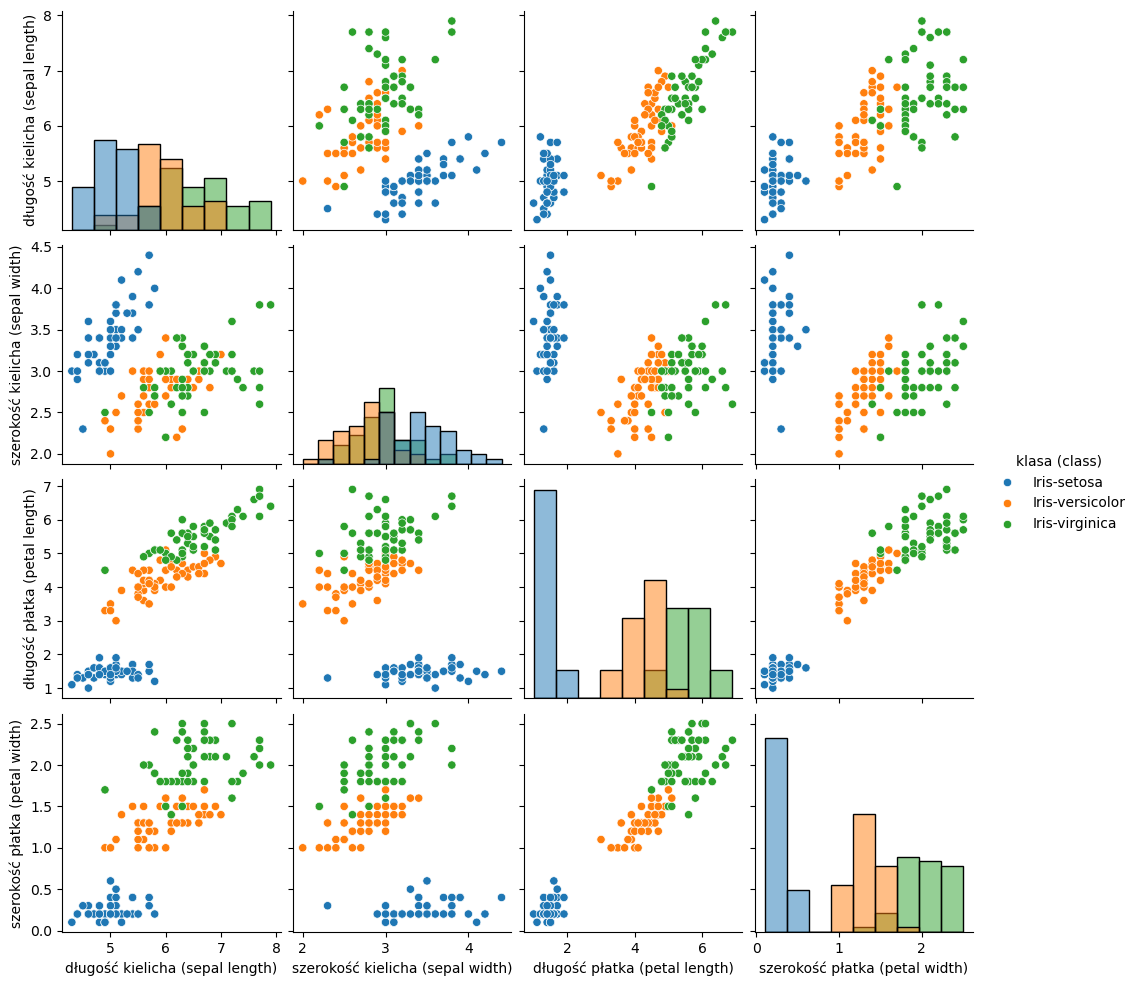

In [123]:
# Import the required dependencies
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the DataFrame
df = df

# Create a pairplot with scatter plots for numerical columns and hue based on iris species
pairplot = sns.pairplot(df, hue='klasa (class)', diag_kind='hist')

# Save the plot as a PNG file
plot_filename = "iris_scatter_plot.png"
pairplot.savefig(plot_filename)

# Declare result variable
result = { "type": "plot", "value": plot_filename }

## Wykresy pudełkowe dla różnych parametrów irysów z uwzględniniem wszystkich analizowanych gatunków

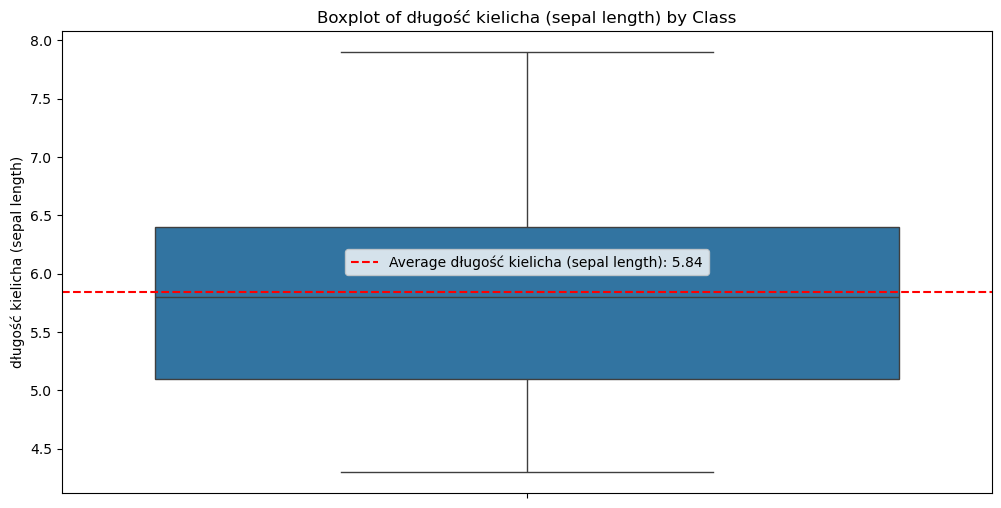

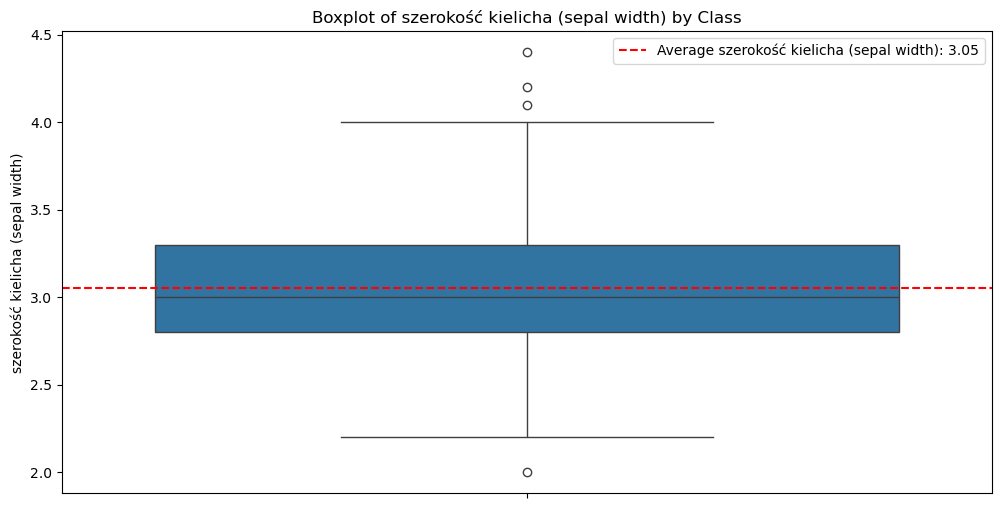

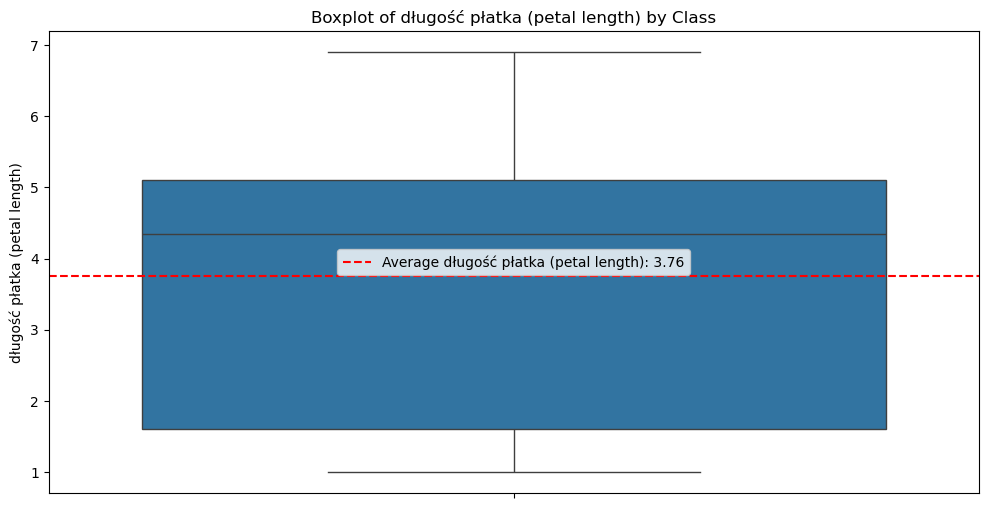

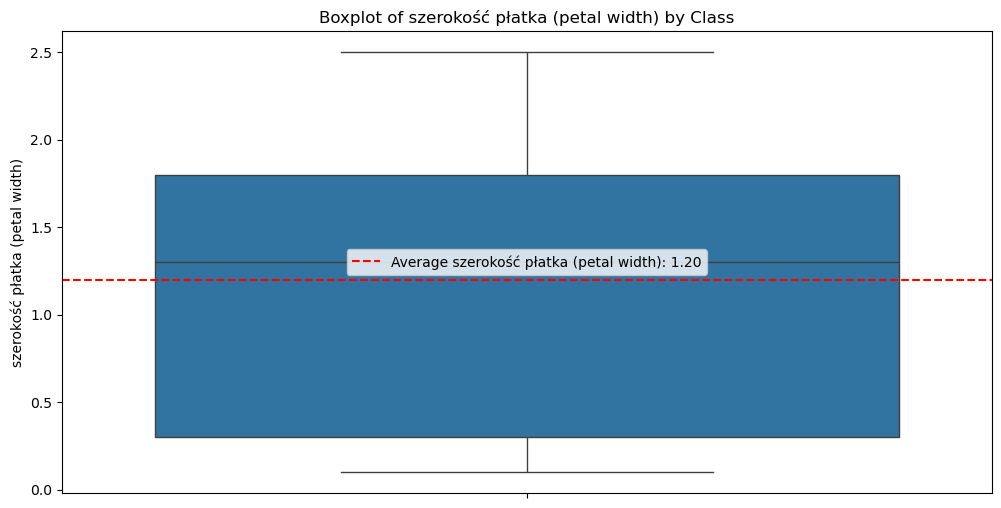

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns

df.columns = df.columns.str.replace('_', ' ')
class_column = 'klasa (class)'
numerical_columns = df.columns.tolist()
numerical_columns.remove(class_column)

for col in numerical_columns:
    plt.figure(figsize=(12, 6))
    sns.boxplot(y=col, data=df)
    mean_val = df[col].mean()
    plt.axhline(mean_val, color='r', linestyle='--', label=f'Average {col}: {mean_val:.2f}')
    plt.title(f'Boxplot of {col} by Class')
    plt.legend()
    plt.savefig(f"{col.replace(' ', '_')}_boxplot.png")

result = {'type': 'plot', 'value': [f"{col.replace(' ', '_')}_boxplot.png" for col in numerical_columns]}

## Wnioski dotyczące rozkładu pomiarów dla wszystkich gatunków irysów
### Długość kielicha
1. Średnia długość kielicha jest wyższa niż mediana dla wszystkich pomiarów.
2. Na wykresie pudełkowym nie widać wartości wyraźnie odstających ani powyżej, ani poniżej średniej oraz mediany
### Szerokość kielicha
1. Średnia szerokość kielicha jest wyższa niż mediana dla wszystkich pomiarów.
2. Na wykresie pudełkowym widać wartości odstające poniżej i powyżej średniej oraz mediany wszystkich pomiarów tego parametru.
### Długość płatka
1. Średnia długość płatka jest niższa niż mediana dla wszytskich pomiarów.
2. Brak wartości wyraźnie odstających ani powyżej, ani poniżej średniej oraz mediany dla wszystkich pomiarów.
### Szerokość płatka
1. Średnia szerokość płatka jest niższa niż mediana dla wszystkich pomiarów.
2. Na wykresie pudełkowym brak wartości odstające poniżej i powyżej średniej oraz mediany wszystkich pomiarów tego parametru.

## Wykresy pudełkowe dla różnych parametrów irysów z uwzględnieniem podziału na gatunki

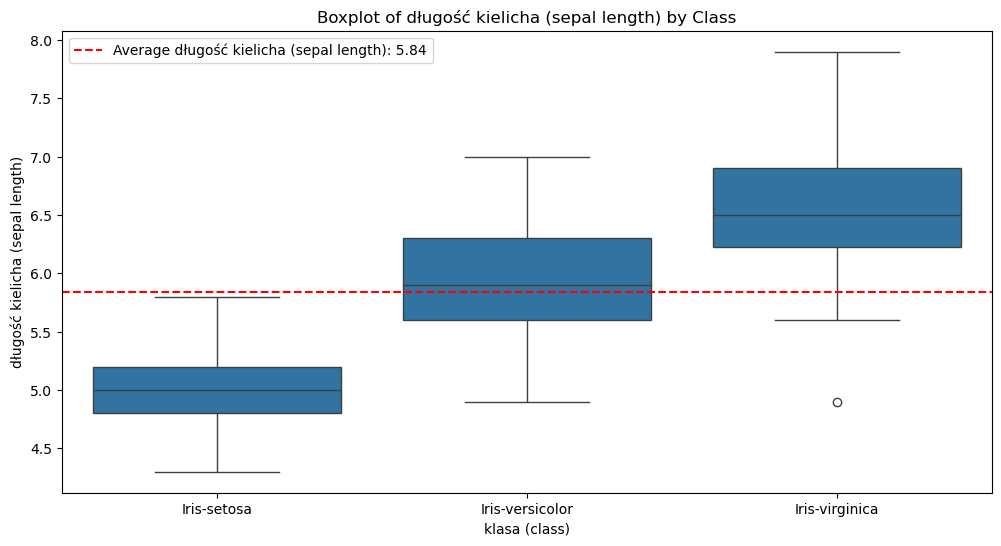

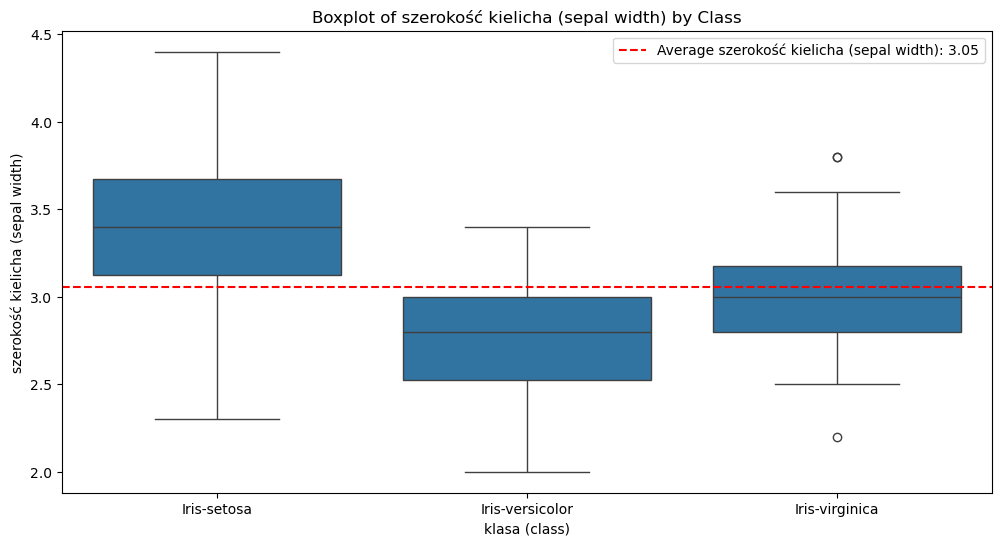

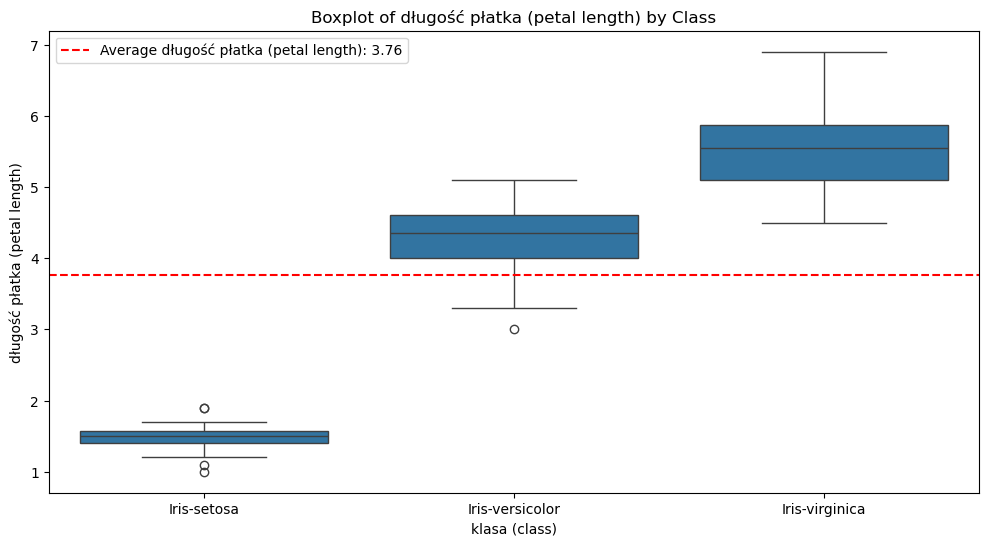

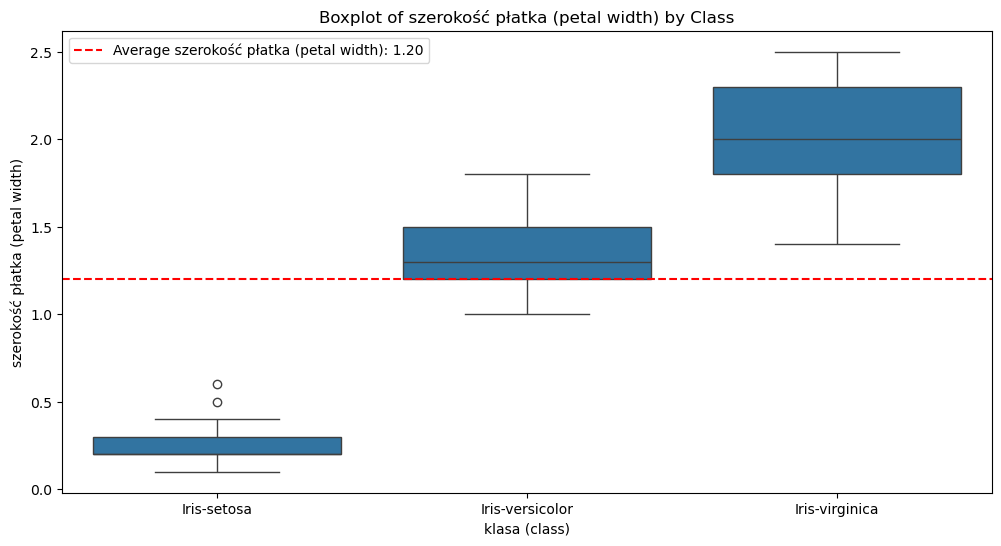

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns

df.columns = df.columns.str.replace('_', ' ')
class_column = 'klasa (class)'
numerical_columns = df.columns.tolist()
numerical_columns.remove(class_column)

for col in numerical_columns:
    plt.figure(figsize=(12, 6))
    sns.boxplot(x=class_column, y=col, data=df)
    mean_val = df[col].mean()
    plt.axhline(mean_val, color='r', linestyle='--', label=f'Average {col}: {mean_val:.2f}')
    plt.title(f'Boxplot of {col} by Class')
    plt.legend()
    plt.savefig(f"{col.replace(' ', '_')}_boxplot.png")

result = {'type': 'plot', 'value': [f"{col.replace(' ', '_')}_boxplot.png" for col in numerical_columns]}


## Porónanie średnich wartości dla różnych parametrów irysów

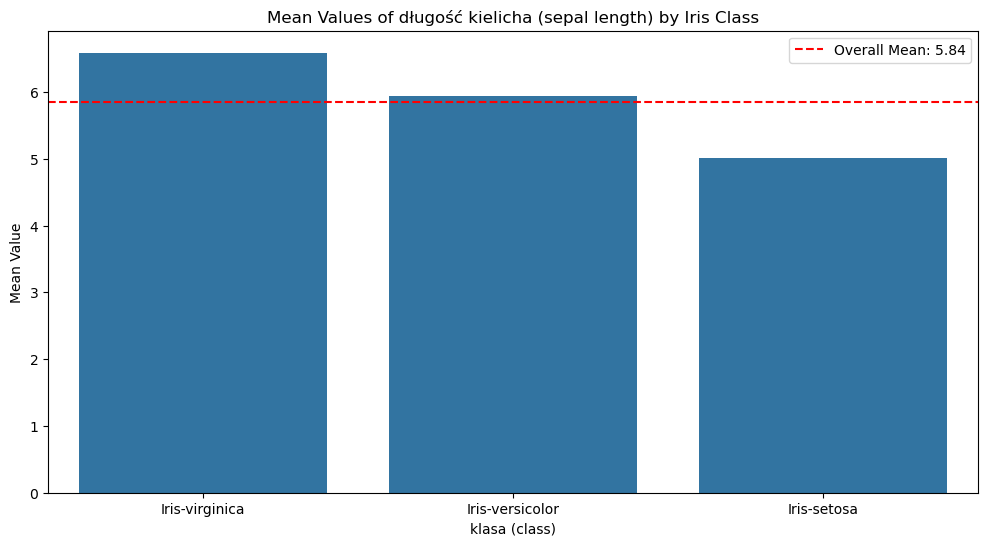

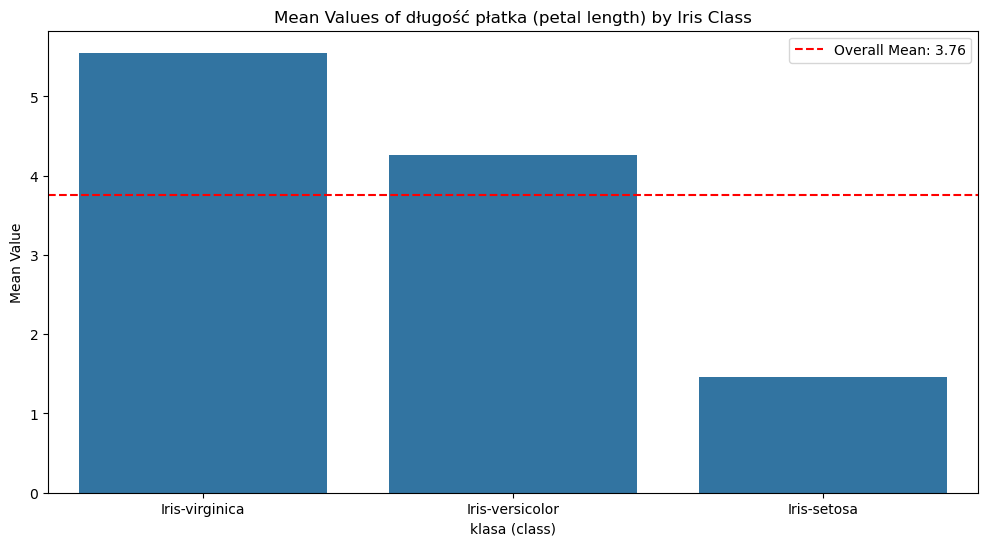

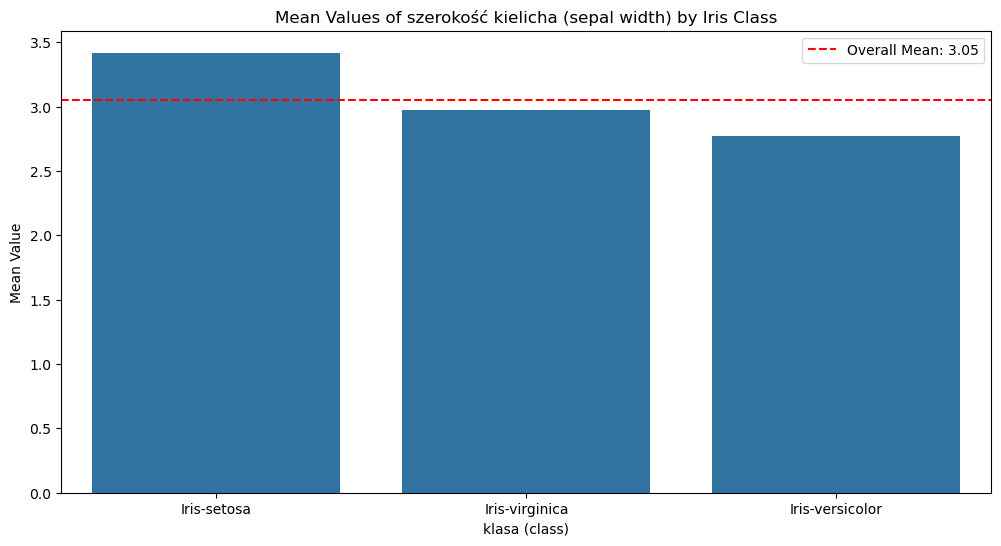

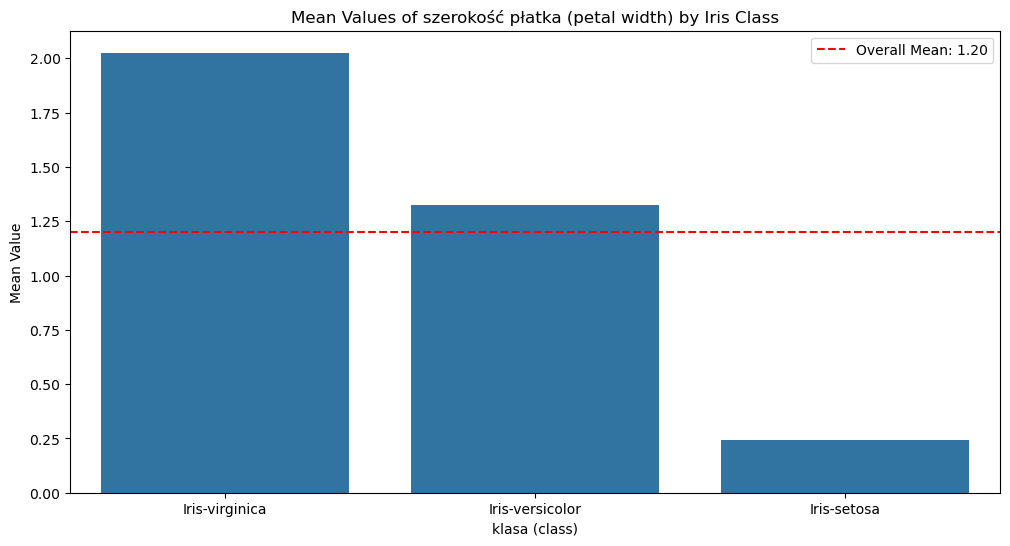

In [46]:
# Import the required dependencies
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the mean values for each numerical column
mean_values = df.groupby("klasa (class)").mean()
overall_mean = df.mean(numeric_only=True).sort_values(ascending=False)

# Plotting
for column in overall_mean.index:
    plt.figure(figsize=(12, 6))
    mean_values = mean_values.sort_values(by=column, ascending=False)
    sns.barplot(x=mean_values.index, y=mean_values[column])
    plt.axhline(y=overall_mean[column], color='r', linestyle='--', label=f'Overall Mean: {overall_mean[column]:.2f}')
    plt.title(f'Mean Values of {column} by Iris Class')
    plt.ylabel('Mean Value')
    plt.legend()
    plt.savefig(f'{column}_mean_plot.png')
    # plt.close()

# Declare result variable
result = { "type": "plot", "value": "plots_saved_as_png" }

## Wnioski dotyczące średnich parametrów analizowanych gatunków irysów

### Średnia długość kielicha
1. Średnia długość kielicha dla wszystkich irysów wynosi ok 5,84 cm.
1. Średnia długość kielicha osiąga najwyższe wartości spośród wszystkich średnich analizowanych parametrów.
2. *Iris-virginica* oraz *Iris-versicolor* osiągają średnie długości kielicha powyżej, a *Iris-setosa* poniżej średniej dla wszystkich gatunków.
### Średnia długość płatka
1. Średnia długość płatka dla wszystkich irysów wynosi ok 3,76 cm.
2. Średnia długość płatka jest niższa niż średnia długość kielicha, ale wyższa niż średnie dla dwóch pozostałych analizowanych parametrów.
3. *Iris-virginica* oraz *Iris-versicolor* osiągają średnie długości płatka powyżej, a *Iris-setosa* poniżej średniej dla wszystkich gatunków.
### Średnia szerkość kielicha
1. Średnia szerkość kielicha dla wszystkich irysów wynosi ok 3,05 cm.
2. Średnia szerkość kielicha jest niższa niż średnia długość kielicha oraz średnia długość płatka, ale wyższa niż średnie dla szerokości płatka.
3. *Iris-virginica* oraz *Iris-versicolor* osiągają średnie szerkości kielicha poniżej, a *Iris-setosa* powyżej średniej dla wszystkich gatunków.
### Średnia szerkość płatka
1. Średnia szerkość kielicha dla wszystkich irysów wynosi ok 1,20 cm.
2. Średnia szerkość kielicha jest najniższa pośród średnich wszystkich badanych parametrów.
3. *Iris-virginica* oraz *Iris-versicolor* osiągają średnie szerokości płatka powyżej, a *Iris-setosa* poniżej średniej dla wszystkich gatunków.


## Porównanie wartości minimalnych i maksymalnych dla różnych parametrów irysów wraz z uwzględnieniem klasy irysów oraz średniej z wszystkich pomiarów

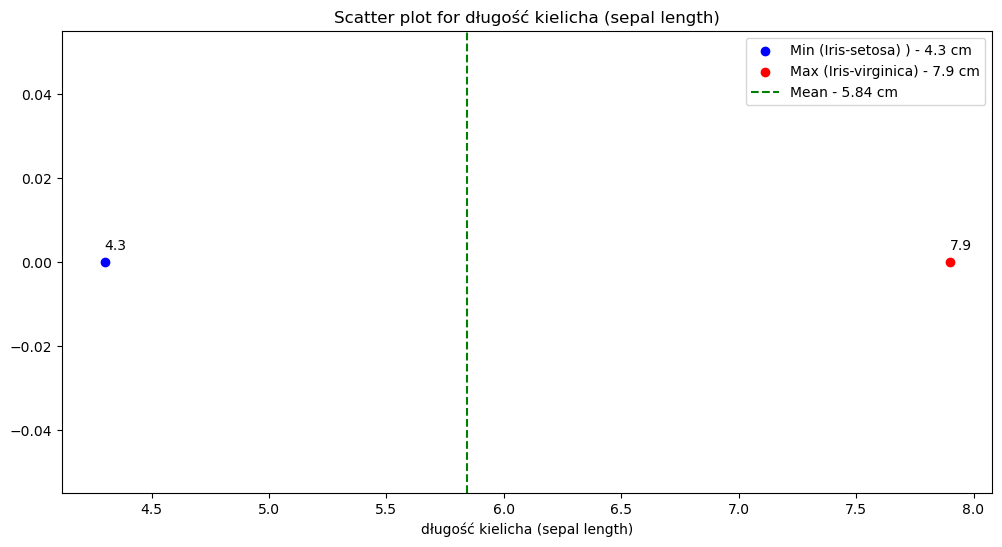

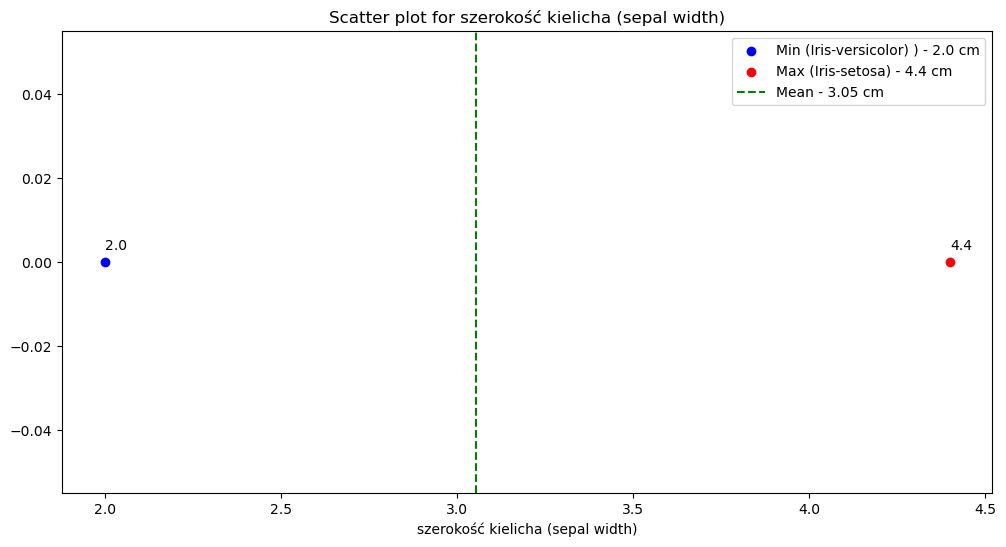

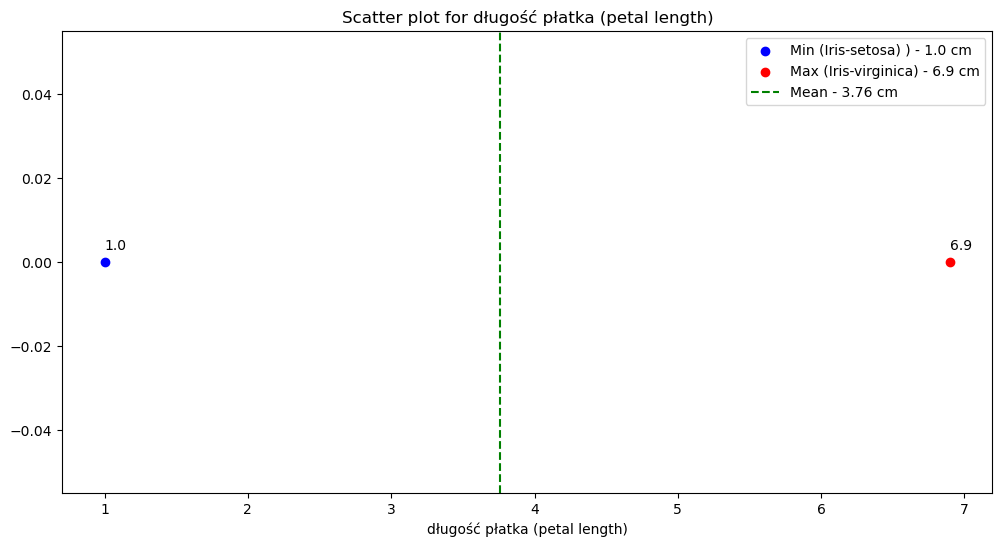

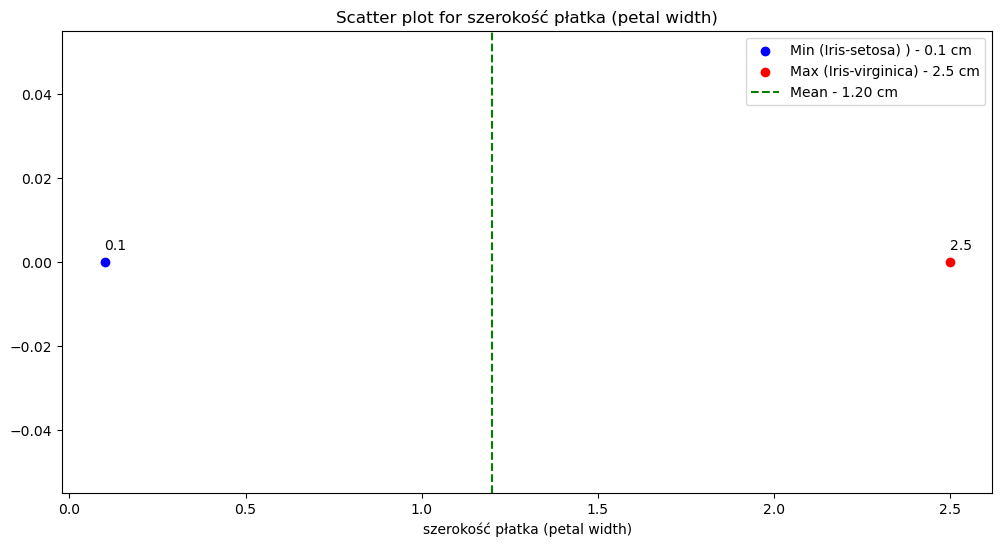

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns

df = df
numeric_columns = df.columns.tolist()
class_column = 'klasa (class)'
numeric_columns.remove(class_column)
plots = {}

# Calculate min, max, and mean for each numeric column
numeric_columns = df.select_dtypes(include=['float64']).columns
min_values = df[numeric_columns].min()
max_values = df[numeric_columns].max()
mean_values = df[numeric_columns].mean()

for col in numeric_columns:
    plt.figure(figsize=(12, 6))
    
    # Plot min value
    min_value = min_values[col]
    min_class = df[df[col] == min_value]["klasa (class)"].values[0]
    plt.scatter(min_value, 0, color='blue', label=f'Min ({min_class}) ) - {min_value} cm')
    plt.annotate(str(min_value), (min_value, 0.003)) 
    
    # Plot max value
    max_value = max_values[col]
    max_class = df[df[col] == max_value]["klasa (class)"].values[0]
    plt.scatter(max_value, 0, color='red', label=f'Max ({max_class}) - {max_value} cm')
    plt.annotate(str(max_value), (max_value, 0.003)) 
    
    # Plot mean value
    mean_value = mean_values[col]
    plt.axvline(mean_value, color='green', linestyle='--', label=f'Mean - {mean_value:.2f} cm')
    
    plt.title(f'Scatter plot for {col}')
    plt.xlabel(col)
    plt.legend()
    
    # Save the plot as a PNG file
    plt.savefig(f'{col}_scatter_plot.png')
    plots[col] = plot_filename
    # plt.close()

# Declare result variable
result = {"type": "plot", "value": plots}

## Podsumowanie analizy

Analizie zostały poddane różne parametry irysów z trzech gatunków (lub inaczej klas): *Iris-virginica*, *Iris-versicolor* oraz *Iris-setosa*. Można zauważyć pewne prawidłowości zarówno analizując wszystkie gatunki irysów razem, jak i dokonując analizy każdego z gatunków osobno. Poniżej przedstawię zbiorcze informacje na temat analizowanych danych.

Analizie zostało poddanych 150 rożnych kwiatów (po 50 dla każdego gatunku). Zbiór danych zawiera informacje o 4 głównych parametrach irysów, takich jak:
- długość kielicha
- szerokość kielicha
- długość płatka
- szerokość płatka

Analizując każdy z powyższych parametrów można zauważyć pewne prawidłowości dla każdego z nich.

### Długość kielicha
1. Średnia wartość dla wszystkich kwiatów to ok. 5,84 cm, zaś mediana wynosi ok. 5,80 cm.
2. Najniższa zanotowana wartość to 4,3 cm (dla kwiata z gatunku *Iris-setosa*), zaś najwyższa wynosi 7,9 cm (dla irysa z gatunku *Iris-virginica*).
3. Spośród analizowanych gatunków najwyższą średnią długość kielicha uzyskały kwiaty z gatunku *Iris-virginica* (ok. 6,59 cm), zaś najniższą średnią długością kielicha charakteryzują się *Iris-setosa* (ok. 5 cm)
### Szerokość kielicha
1. Średnia wartość dla wszystkich kwiatów to ok. 3,05 cm, zaś wynosi mediana ok. 3 cm.
2. Najniższa zanotowana wartość to 2 cm (dla kwiata z gatunku *Iris-versicolor*), zaś najwyższa wynosv 4,4 cm (dla irysa z gatunku *Iris-setosa*).
3. Spośród analizowanych gatunków najwyższą średnią szeokość kielicha uzyskały kwiaty z gatunku *Iris-setosa* (ok. 3,42 cm), zaś najniższą średnią długością kielicha charakteryzują się *Iris-versicolor* (ok. 2,77 cm)
### Długość płatka
1. Średnia wartość dla wszystkich kwiatów to ok. 3,76 cm, zaś mediana synosi ok. 4,35 cm.
2. Najniższa zanotowana wartość to 1 cm (dla kwiata z gatunku *Iris-setosa*), zaś najwyższa wynosi 6,9 cm (dla irysa z gatunku *Iris-virginica*).
3. Spośród analizowanych gatunków najwyższą średnią długość płatka uzyskały kwiaty z gatunku *Iris-virginica* (ok. 5,55 cm), zaś najniższą średnia długością płatka charakteryzują się *Iris-setosa* (ok. 1,47 cm)
### Szerokość płatka
1. Średnia wartość dla wszystkich kwiatów to ok. 1,2 cm, zaś mediana wynosi ok. 1,3 cm.
2. Najniższa zanotowana wartość to 0,1 cm (dla kwiata z gatunku *Iris-setosa*), zaś najwyższa wynosi 2,5 cm (dla irysa z gatunku *Iris-virginica*).
3. Spośród analizowanych gatunków najwyższą średnią szerokość płatka uzyskały kwiaty z gatunku *Iris-virginica* (ok. 2,02 cm), zaś najniższą średnia szerokością płatka charakteryzują się *Iris-setosa* (ok. 0,24 cm)

## Wnioski
Zależnie od parametrów kwiatów na których nam zależy możemy wybrać kwiaty róznych gatunków. Przykładowo kwiaty z gatunku *Iris-virginica* uzyskują najwyższe średnie wartości pomiarów pod względem długości płatka oraz kielicha, a także szerokości kielicha. Dodatkowo kwiaty z tego gatunku uzyskały najwyższe odnotowane wartości pośród wszystkich analizowanych kwiatów pod względem długości płatka oraz kielicha, a także szerokości kielicha.

Irysy z gatunku *Iris-setosa* mają najwyższe średnie szerokości kielicha, za to ich płatki są średnio najkrótsze i najwęższe, a także kielichy ich kwiatów są średnio najkrótsze. 

Jeśli zaś chodzi o parametry kwiatów z gatunku *Iris versicolor*, to średnio ich parametry plasują się pomiędzy *Iris-virginica* oraz *Iris-setosa*, z wyjątkiem szerokości kielicha, która dla tego gatunku jest średnio najmniejsza spośród trzech analizowanych gatunków.
